# Noise on IBM's Open-plan devices

**Part 2 of 3: Noise** · [← Part 1: How it works](01_how_it_works.ipynb) ·
[Part 3: Hardware →](03_hardware.ipynb) · [README](../README.md)

**Question.** Real quantum computers make errors. Does the detector's signal
survive them on the three devices of IBM's free Open plan (**ibm_kingston,
ibm_marrakesh, ibm_fez**)?

**Result.** The original 22-qubit circuit does not: gate noise erases its
signal on all three. The 12-qubit circuit's signal survives on all three. But
the noise measured in each simulated run, from its calibration circuits, is
larger than IBM's published error rates predict, so the noisier devices need
many more shots than the published data suggests. A losing line that noise
pushes over the cutoff is always caught by the classical check, so noise never
produces a wrong winner. Section 5 summarizes the results.

Everything here is simulated on *fake backends*: Qiskit's copies of the real
devices, each holding a snapshot of the device's calibration data. Two levels
of realism, then real hardware in Part 3:

1. **Published-data model** (section 2): IBM's published error rates predict
   the counts in milliseconds.
2. **Noise-model simulator** (section 3): every gate error, qubit decay and
   readout error simulated, with the detector measuring the noise in the same
   job, exactly as a hardware run would.

Terms such as ESP, ε and readout matrix are in the
[glossary of Part 1](01_how_it_works.ipynb#Glossary). Run time: a few minutes.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from qttt import plots
from qttt.backends import IdealBackend, get_backend
from qttt.board import EMPTY, O, X, classical_winning_lines
from qttt.detector import DEFAULT_BUDGET, DEFAULT_SHOTS, detect_winners
from qttt.noise import NoiseProfile

SEED = 4903
SHOTS = DEFAULT_SHOTS
BUDGET = DEFAULT_BUDGET
DEVICES = ("fake_kingston", "fake_marrakesh", "fake_fez")  # snapshots of the free-plan devices
VARIANT_NAMES = {"player": "12-qubit", "full": "22-qubit"}

_ = EMPTY
CASES = {  # X has just moved on all three
    "Single win": (X, O, X,
                   O, X, O,
                   _, _, X),
    "Double win": (X, X, X,
                   X, O, O,
                   X, O, O),
    "No win": (X, O, X,
               X, O, O,
               O, X, X),
}
WINNERS = {name: classical_winning_lines(board, X) | classical_winning_lines(board, O) for name, board in CASES.items()}


def shots_for_1pct(profile):
    """Shots per board for at most 1% missed wins with this noise."""
    return profile.shots_needed(0.01, BUDGET) or "more than 16384"


def cases_for(variant):
    """(board, player) pairs: the 12-qubit circuit checks the player who just moved, the 22-qubit one both."""
    return [(board, X if variant == "player" else None) for board in CASES.values()]

## 1. The devices

Each version of the circuit is compiled once per device (5 compiler seeds,
best kept). The 12-qubit circuit is compiled with and without the ancilla
qubit and the one with the higher score is kept (Part 1, section 9), so the
choice can differ by device. ESP is the chance that no gate fails, from the
device's published error rates.

In [2]:
backends = {name.removeprefix("fake_"): get_backend(name, seed=SEED, transpile_seeds=5) for name in DEVICES}
rows = []
for label, backend in backends.items():
    m12 = backend.metrics(backend.search_template("player"))
    m22 = backend.metrics(backend.search_template("full"))
    rows.append((label, backend.calibration_date()[:10], m12.two_qubit_gates, m22.two_qubit_gates,
                 "yes" if m12.ancilla else "no", f"{10 ** m12.log10_esp:.1%}", f"{10 ** m22.log10_esp:.1e}"))
plots.table(["device", "calibration snapshot", "two-qubit gates, 12-qubit", "two-qubit gates, 22-qubit",
             "ancilla", "ESP, 12-qubit", "ESP, 22-qubit"], rows, "llrrlrr")

| device | calibration snapshot | two-qubit gates, 12-qubit | two-qubit gates, 22-qubit | ancilla | ESP, 12-qubit | ESP, 22-qubit |
| :--- | :--- | ---: | ---: | :--- | ---: | ---: |
| kingston | 2026-04-15 | 481 | 2702 | no | 44.5% | 1.9e-03 |
| marrakesh | 2025-02-26 | 413 | 2702 | yes | 29.4% | 9.8e-05 |
| fez | 2025-02-26 | 413 | 2784 | yes | 24.2% | 1.1e-05 |

## 2. Published-data model

**Claim:** from IBM's published error rates alone, the 22-qubit circuit is
hopeless on every device and the 12-qubit circuit is comfortable.

The model has two parts, both built from the device's calibration data by
`NoiseProfile.from_backend`:

- **Gate noise ε = 1 − ESP:** the share of shots that gate errors scatter
  evenly over the 8 lines.
- **Readout:** each of the 3 line qubits misreads 0 as 1 or 1 as 0 with its own
  probability; together they form an 8×8 *readout matrix* A.

<details><summary>Details</summary>

Predicted shares = A · [(1 − ε) · ideal + ε / 8]. Each line gets its own
cutoff (lines that readout bias pushes up need more counts), and the profile
predicts how often wins are missed. Below, 1024 shots are drawn from each
prediction and scored like a real run. (The profile measured in the job, in
section 3, also gives each bit of the line index its own signal factor;
published data has nothing to fit them from.)
</details>

**Reading the bar charts:** each bar is the share of shots measured on a line
index. Green: the board's real winning lines. Gray: losing lines. Orange,
hatched and marked x: a losing line that reached its cutoff, so it was flagged
and then rejected by the classical check. The black tick on each bar is that
line's cutoff, and the dotted line is 1/8, an even spread over all 8 lines.

| version | device | ε | worst chance of missing a win at 1024 shots | shots for ≤1% misses |
| :--- | :--- | ---: | ---: | ---: |
| 12-qubit | kingston | 0.555 | 0.00% | 64 |
| 12-qubit | marrakesh | 0.706 | 0.00% | 128 |
| 12-qubit | fez | 0.758 | 0.00% | 192 |
| 22-qubit | kingston | 0.998 | 97.30% | more than 16384 |
| 22-qubit | marrakesh | 1.000 | 97.93% | more than 16384 |
| 22-qubit | fez | 1.000 | 97.87% | more than 16384 |

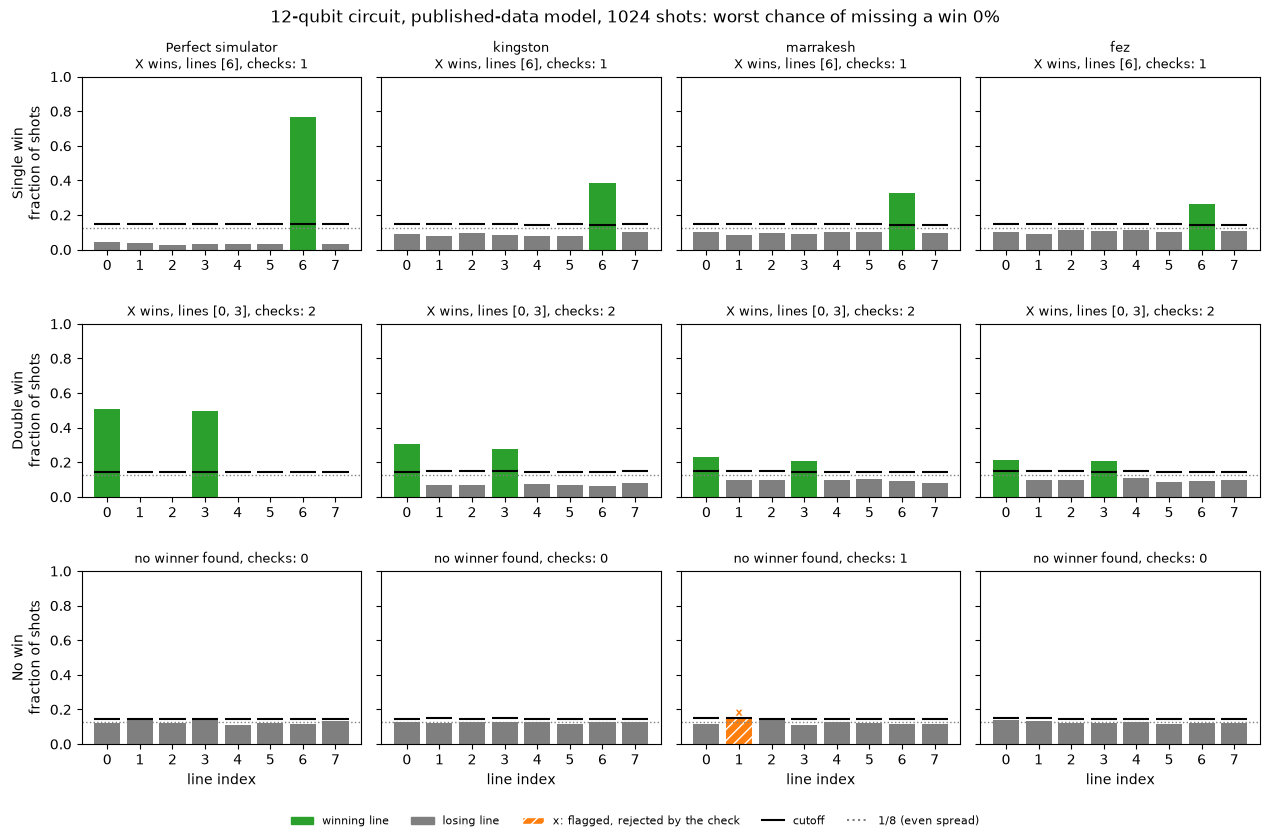

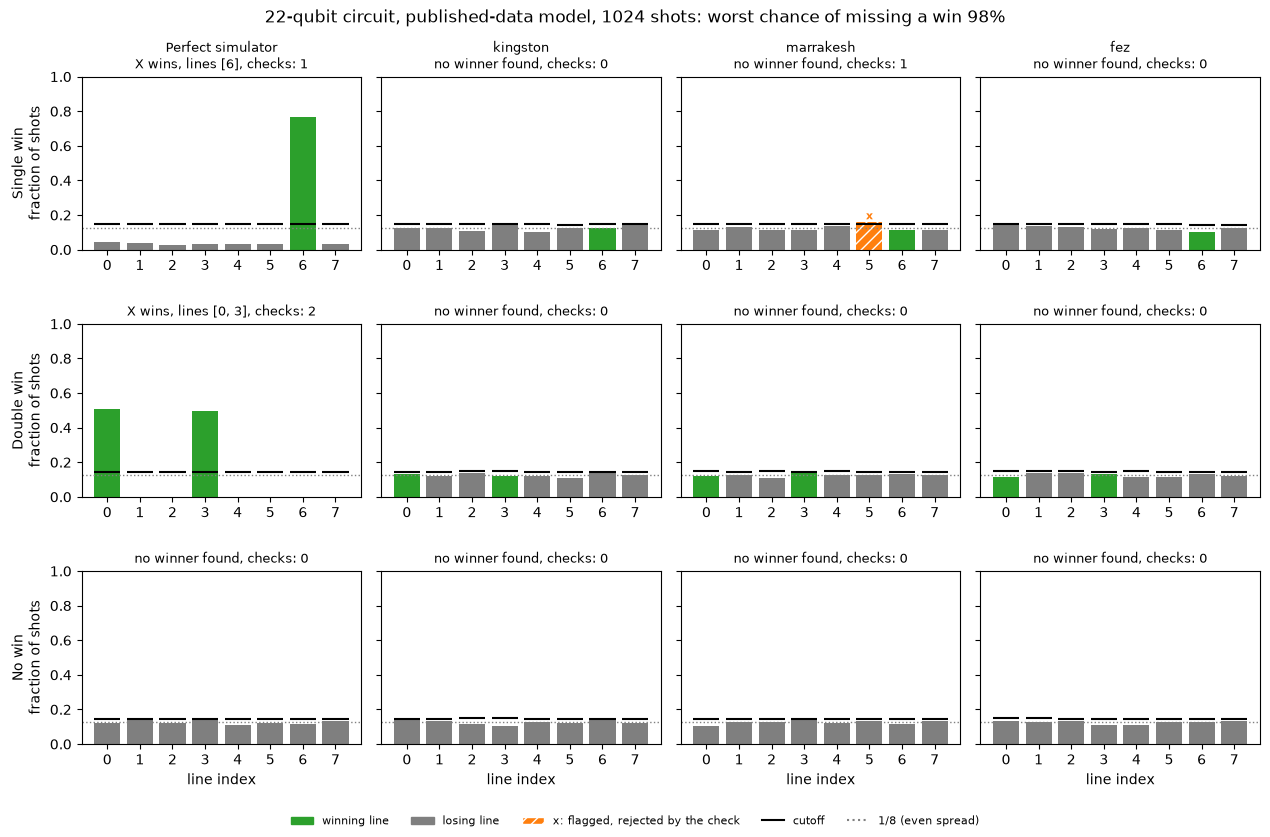

In [3]:
rng = np.random.default_rng(SEED)
ideal_cutoffs = NoiseProfile.from_ideal().cutoffs(SHOTS, BUDGET)
published = {v: {label: NoiseProfile.from_backend(b, v) for label, b in backends.items()} for v in VARIANT_NAMES}

display(plots.table(
    ["version", "device", "ε", f"worst chance of missing a win at {SHOTS} shots", "shots for ≤1% misses"],
    [(VARIANT_NAMES[v], label, f"{p.epsilon:.3f}", f"{p.miss_rates(SHOTS, BUDGET).worst:.2%}",
      shots_for_1pct(p))
     for v in VARIANT_NAMES for label, p in published[v].items()], "llrrr"))

ideal_counts = {name: r.run.counts for name, r in zip(
    CASES, detect_winners(cases_for("player"), shots=SHOTS, backend=IdealBackend(seed=SEED)))}
for variant in VARIANT_NAMES:
    columns = {"Perfect simulator": (ideal_cutoffs, ideal_counts)}
    for label, profile in published[variant].items():
        drawn = {}
        for name in CASES:
            p = np.array(profile.predicted_for(WINNERS[name]))
            drawn[name] = tuple(int(c) for c in rng.multinomial(SHOTS, p / p.sum()))
        columns[label] = (profile.cutoffs(SHOTS, BUDGET), drawn)
    worst = max(p.miss_rates(SHOTS, BUDGET).worst for p in published[variant].values())
    plots.count_grid(columns, CASES, WINNERS, f"{VARIANT_NAMES[variant]} circuit, published-data model, {SHOTS} "
                     f"shots: worst chance of missing a win {worst:.0%}")
    plt.show()

**What to notice:** the 22-qubit circuit needs thousands of two-qubit gates,
so gate noise erases the signal on every device: every line sits near the
dotted 1/8 line and wins are missed. The 12-qubit circuit needs a few hundred,
and the winning lines still stand clear of their cutoffs.

## 3. Noise-model simulator, measuring the noise in the same job

**Claim:** with every error simulated, the 12-qubit circuit still finds wins,
but the noise is heavier than the published data says.

This runs `detect_winners` with its default settings, exactly as on real
hardware: one job holds 20 *calibration circuits* next to the three boards,
and the noise profile is fitted from them when the job is back. About a
minute per device.

<details><summary>What the calibration circuits are, and how the cutoffs are set</summary>

- 8 readout circuits: each line index prepared directly on the line qubits,
  which gives the readout matrix;
- a board with a known winner on each of the 8 lines (each bit of the line
  index is 1 on four of them), which gives ε and a signal factor per bit;
- two boards without a winner, and two double wins, which give a factor for
  double wins.

Each line's cutoff is set high enough that a losing line rarely reaches it,
including the pooled share the calibration boards measured on it as a loser,
plus a margin for that share's uncertainty and its spread between boards.
</details>

| device | board | counts per line index | winner | rejected |
| :--- | :--- | :--- | :--- | :--- |
| kingston | Single win | (98, 75, 98, 91, 112, 99, 344, 107) | X | [] |
| kingston | Double win | (330, 98, 89, 232, 78, 62, 71, 64) | X | [] |
| kingston | No win | (126, 137, 140, 141, 112, 112, 125, 131) | none | [] |
| marrakesh | Single win | (119, 124, 137, 101, 112, 121, 186, 124) | X | [] |
| marrakesh | Double win | (199, 113, 121, 165, 112, 107, 103, 104) | X | [] |
| marrakesh | No win | (158, 108, 135, 118, 121, 128, 121, 135) | none | [] |
| fez | Single win | (130, 131, 117, 107, 127, 119, 180, 113) | X | [] |
| fez | Double win | (177, 122, 128, 154, 111, 120, 111, 101) | none | [] |
| fez | No win | (135, 127, 122, 110, 126, 144, 137, 123) | none | [] |

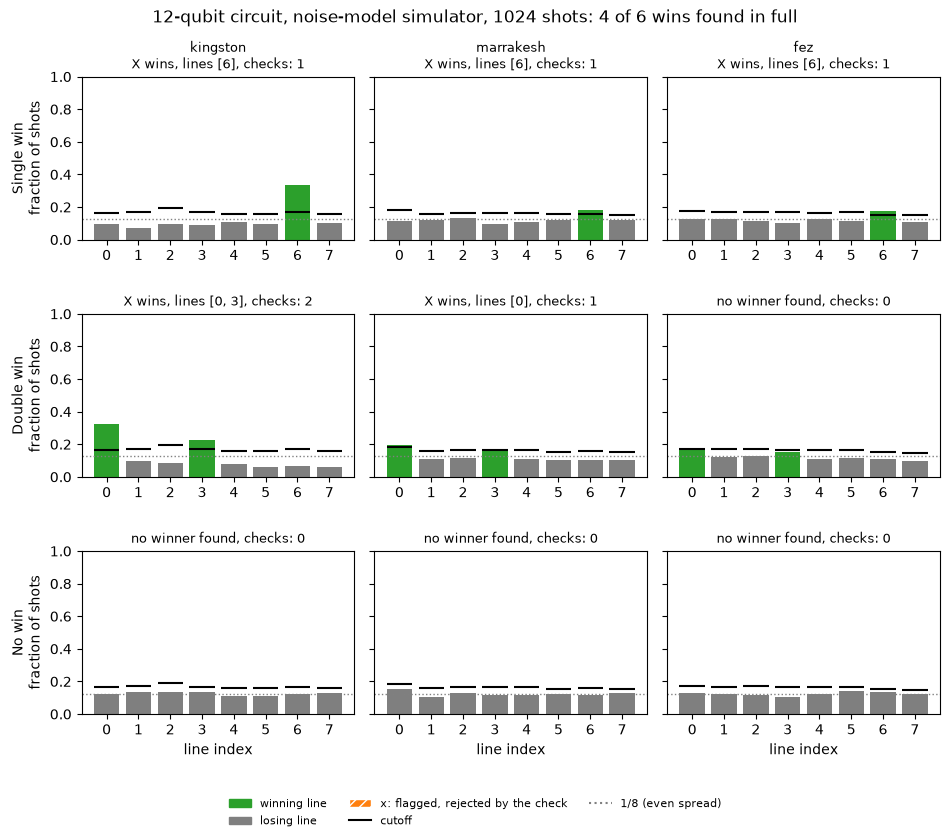

In [4]:
measured, simulated, results_by_device = {}, {}, {}
for label, backend in backends.items():
    results = detect_winners(cases_for("player"), shots=SHOTS, budget=BUDGET, backend=backend)
    results_by_device[label] = dict(zip(CASES, results))
    measured[label] = results[0].profile
    simulated[label] = (results[0].cutoffs, {name: r.run.counts for name, r in zip(CASES, results)})

display(plots.table(["device", "board", "counts per line index", "winner", "rejected"],
                    [(label, name, r.run.counts, r.winner or "none", list(r.rejected))
                     for label, by_case in results_by_device.items() for name, r in by_case.items()], "lllll"))
with_winner = [(name, r) for by_case in results_by_device.values() for name, r in by_case.items() if WINNERS[name]]
found = sum(set(r.lines) == WINNERS[name] for name, r in with_winner)
plots.count_grid(simulated, CASES, WINNERS, f"12-qubit circuit, noise-model simulator, {SHOTS} shots: "
                 f"{found} of {len(with_winner)} wins found in full")
plt.show()

## 4. Published vs measured noise

**Finding: IBM's published calibration data underestimates the noise this
circuit sees** (by how much is printed below). ESP counts only gate errors,
while the simulator also lets qubits decay during gates and while they wait.
Published readout errors can also describe a bias the device does not have,
which puts the per-line cutoffs on the wrong lines. Measuring both in the same
job avoids that, and it works on any provider, including ones that publish
nothing.

Measured ε is above the published 1 − ESP on every device, by **0.03 to 0.14**.

| device | ε published | ε measured | shots for ≤1% misses, published | shots for ≤1% misses, measured |
| :--- | ---: | ---: | ---: | ---: |
| kingston | 0.555 | 0.585 | 64 | 256 |
| marrakesh | 0.706 | 0.845 | 128 | 1536 |
| fez | 0.758 | 0.884 | 192 | 7616 |

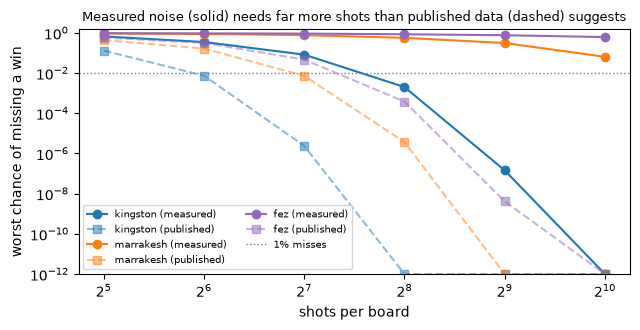

In [5]:
gaps = {label: measured[label].epsilon - published["player"][label].epsilon for label in backends}
display(plots.markdown(f"Measured ε is above the published 1 − ESP on every device, by "
                       f"**{min(gaps.values()):.2f} to {max(gaps.values()):.2f}**."))
display(plots.table(["device", "ε published", "ε measured", "shots for ≤1% misses, published",
                     "shots for ≤1% misses, measured"],
                    [(label, f"{published['player'][label].epsilon:.3f}", f"{measured[label].epsilon:.3f}",
                      shots_for_1pct(published["player"][label]), shots_for_1pct(measured[label]))
                     for label in backends], "lrrrr"))

shot_counts = [32, 64, 128, 256, 512, 1024]
curves = {label: ([measured[label].miss_rates(n, BUDGET).worst for n in shot_counts],
                  [published["player"][label].miss_rates(n, BUDGET).worst for n in shot_counts]) for label in backends}
plots.miss_rate_curves(curves, shot_counts, "Measured noise (solid) needs far more shots than published data "
                       "(dashed) suggests")
plt.show()

## 5. Findings

In [6]:
def shortfall(name, r):
    """How a board with a winner fell short, or None when every winning line was found."""
    if set(r.lines) == WINNERS[name]:
        return None
    return f"found only one line of the {name.lower()}" if r.lines else f"missed the {name.lower()}"


lines = []
for label, by_case in results_by_device.items():
    short = [s for name, r in by_case.items() if WINNERS[name] and (s := shortfall(name, r))]
    lines.append(f"- **{label}:** " + ("; ".join(short) if short else "found every winning line")
                 + f"; for at most 1% misses it needs **{shots_for_1pct(measured[label])} shots** "
                 f"by the measured noise, against {shots_for_1pct(published['player'][label])} "
                 "by the published data.")
wrong = [r for by_case in results_by_device.values() for name, r in by_case.items() if not r.lines <= WINNERS[name]]
assert not wrong
plots.markdown(
    f"At {SHOTS} shots, with the noise measured in the same job:\n\n" + "\n".join(lines) + "\n\n"
    "- Every flagged losing line was rejected by the classical check: noise never produced a wrong winner.\n"
    f"- The published data understates the noise by {min(gaps.values()):.2f} to {max(gaps.values()):.2f} in ε, "
    "so a shot count chosen from it would miss wins on the noisier devices; Part 3 chooses shots from a "
    "short calibration job on the device instead.")

At 1024 shots, with the noise measured in the same job:

- **kingston:** found every winning line; for at most 1% misses it needs **256 shots** by the measured noise, against 64 by the published data.
- **marrakesh:** found only one line of the double win; for at most 1% misses it needs **1536 shots** by the measured noise, against 128 by the published data.
- **fez:** missed the double win; for at most 1% misses it needs **7616 shots** by the measured noise, against 192 by the published data.

- Every flagged losing line was rejected by the classical check: noise never produced a wrong winner.
- The published data understates the noise by 0.03 to 0.14 in ε, so a shot count chosen from it would miss wins on the noisier devices; Part 3 chooses shots from a short calibration job on the device instead.

In [7]:
# The README's results table reads these numbers (scripts/readme_results.py), so it matches this notebook.
summary = {"shots": SHOTS, "budget": BUDGET, "seed": SEED, "devices": {
    label: {"backend": backend.name, "calibration_date": backend.calibration_date(),
            "epsilon_published": published["player"][label].epsilon, "epsilon_measured": measured[label].epsilon,
            "shots_needed_published": published["player"][label].shots_needed(0.01, BUDGET),
            "shots_needed_measured": measured[label].shots_needed(0.01, BUDGET)}
    for label, backend in backends.items()}}
Path("../results/noise_summary.json").write_text(json.dumps(summary, indent=2) + "\n")

902

Each board here is a single run, so one miss says little on its own; the
noise profiles, fitted from 20 calibration circuits per device, say more.
These are simulations of calibration snapshots: the real devices drift from
day to day.

---

[← Part 1: How it works](01_how_it_works.ipynb) · [README](../README.md) ·
**Next: [Part 3: Hardware →](03_hardware.ipynb)**